# Lab 2 - Decision Trees

## 1. Introduction and Setup

### 1.1 Instructions

* Run all the code cells in chronological order.
* Put your names and student numbers in the indicated cell in the exact indicated format.
* You cannot use additional libraries to the ones imported already for you.
* Your answers must be placed in the indicated answer code cells and must follow the requested format exactly.
* Code cells containing the comment `# STUDENT ANSWER` are answer code cells.
* Do not delete the answer code cells and recreate them as they have custom metadata used by the automarker. If you accidentally delete one, you must redownload the notebook.
* **Execution Order**: Students must run all prior cells in chronological order. Specific cell dependencies will be highlighted for each task.
* **Determinism Constraint**: Students must not alter any `np.random.seed()` calls. Every call to a random function within this lab is immediately preceded by a seed to ensure identical outputs across multiple executions.

### 1.2 Public Test Cases

The 'public test cases' are used for you to check your answers. Hidden test cases using different dataset values will be used to calculate your mark.

### 1.3 Learning Objectives

By completing this lab, you will be able to:

* **Analyse and Intuit Data:** Use data visualisation to identify clear survival trends based on historical context, establishing an intuitive baseline.
* **Quantify Uncertainty:** Implement Shannon Entropy ($H(p)$) to mathematically measure the randomness within different dataset partitions.
* **Evaluate Feature Variables:** Calculate Information Gain ($Gain(D,F)$) to determine the discriminating power of categorical features.
* **Handle Continuous Variables:** Discover the optimal threshold to discretise continuous values by evaluating potential split-points.
* **Construct the ID3 Tree:** Implement the recursive ID3 algorithm to build a deterministic decision tree represented as a nested dictionary.
* **Perform Inference and Understand Pruning:** Develop a traversal algorithm to classify unseen passengers and conceptualise how pruning prevents overfitting.

### 1.4 Imports

You are not allowed to import additional libraries to the ones specified below.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pprint

## Student Details

In [24]:
# STUDENT DETAILS
student_names = ["Mpho Murashiwa"] # List of strings containing student names
student_nos = ["2540206"] # List of strings containing student nos

assert len(student_names) == len(student_nos), "student_names not of same length as student_nos"

---

## 2. Historical Context and Visual Intuition

In this lab, we will utilise the famous Titanic dataset. During the tragic sinking of the Titanic in 1912, a strict "women and children first" evacuation protocol was enforced. This historical context provides us with a strong intuitive baseline: we expect that gender and age will be highly discriminative features when predicting passenger survival. We will mathematically prove this intuition using the ID3 algorithm.

### 2.1 Data Loading

*Requires: Cell 1.4*

In [25]:
# DO NOT MODIFY
# Load dataset and drop missing values for simplicity
df = sns.load_dataset("titanic")
features_to_keep = ['survived', 'sex', 'pclass', 'embarked', 'age', 'fare']
df = df[features_to_keep].dropna().reset_index(drop=True)

# Deterministic train/test split
np.random.seed(42)
indices = np.random.permutation(len(df))
split_idx = int(0.8 * len(df))

train_df = df.iloc[indices[:split_idx]].copy()
test_df = df.iloc[indices[split_idx:]].copy()

print(f"Training data shape: {train_df.shape}")

Training data shape: (569, 6)


### 2.1.1 Dataset Dictionary

For your reference, the features we have extracted from the dataset represent the following:

* **survived:** The target variable we are trying to predict (0 = Died, 1 = Survived).
* **pclass:** Passenger Class. This acts as a proxy for socio-economic status (1 = 1st Class/Upper, 2 = 2nd Class/Middle, 3 = 3rd Class/Lower).
* **sex:** The gender of the passenger (categorical).
* **embarked:** The port where the passenger boarded the ship (C = Cherbourg, Q = Queenstown, S = Southampton).
* **age:** The age of the passenger in years (a continuous numeric variable).
* **fare:** The price paid for the ticket (a continuous numeric variable).

### 2.2 Question 1: Visualisation

*Requires: Cell 2.1*

Visualise the survival rates grouped by `sex` and `pclass` to establish your intuition. Use seaborn's `barplot` with `train_df`.

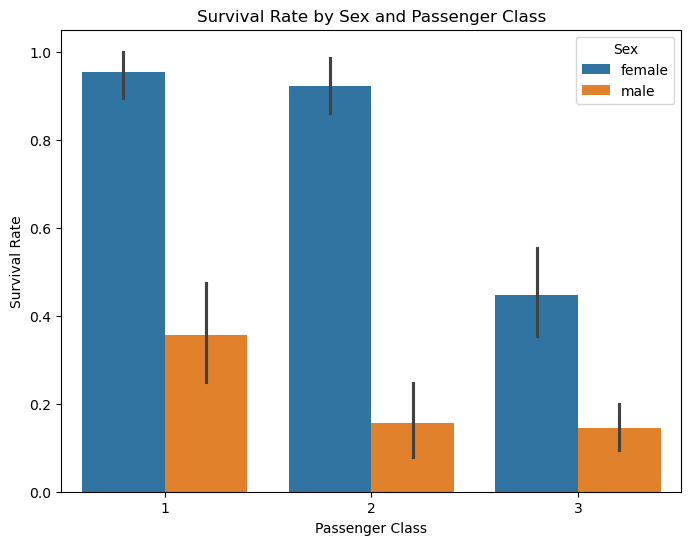

In [26]:
# STUDENT ANSWER
plt.figure(figsize=(8,6))

sns.barplot(
    data=train_df,
    x='pclass',
    y='survived',
    hue='sex'
)

plt.title("Survival Rate by Sex and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.legend(title="Sex")

plt.show()

### 2.3 Question 2: Intuition vs Mathematics

*Requires: Cell 2.2*

Based on your visualisation and the historical protocol, which categorical feature appears to have the strongest discriminating power (i.e., splitting on it would result in branches that are far more ordered and pure than before the split, thus wasting less computation up front)?

* a) `sex`
* b) `embarked`
* c) `pclass`

Assign your chosen letter as a string to the variable `q2_ans`.

In [27]:
# STUDENT ANSWER
q2_ans = "a"

# DO NOT MODIFY BELOW
assert q2_ans in ["a", "b", "c"], "Q2 Public Test Case Failed: Invalid value"
print("Q2 Public Test Case Passed")

Q2 Public Test Case Passed


---

## 3. The Mathematics of Splits

### 3.1 Question 3: Entropy Calculation

*Requires: Cell 2.1*

Entropy ($H(p)$) is a measure of randomness or uncertainty in a system. Lower entropy is better, as it means we can make more accurate predictions.

Implement the `calc_entropy` function. It takes a pandas Series (e.g., the target column) and returns the corresponding entropy as calculated using the equation from your lectures:


$$H(p)=-\sum_{i=1}^{n}p_{i}\log_{2}p_{i}$$

In [28]:
# STUDENT ANSWER
def calc_entropy(labels):
    """
    Calculates the entropy of a given set of labels.
    """
    assert type(labels) == pd.Series, f"labels is of the wrong type: {type(labels)}"

    # Get probabilities of each class
    probs = labels.value_counts(normalize=True)
    
    entropy =-np.sum(probs * np.log2(probs))

    return float(entropy)

# DO NOT MODIFY BELOW
q3_ans = calc_entropy(train_df['survived'])
EXPECTED_ENTROPY = 0.9723

assert isinstance(q3_ans, float), "Q3 Public Test Case Failed: Wrong type"
assert np.isclose(q3_ans, EXPECTED_ENTROPY, atol=1e-3), "Q3 Public Test Case Failed: Incorrect entropy value"
print(f"Entropy of the root dataset: {q3_ans:.4f}")
print("Q3 Public Test Case Passed")

Entropy of the root dataset: 0.9724
Q3 Public Test Case Passed


### 3.2 Question 4: Information Gain

*Requires: Cell 3.1*

Here you will implement $Gain(D, F)$.

Implement the `calc_information_gain` function, which takes as input:
- `data`: the dataset (or subset of the dataset) represented as a Pandas dataframe
- `feature`: the feature variable
- `target`: the name of the target variable - i.e. "PlayTennis"

and outputs the information gain obtained when splitting the data off the given feature. Use the entropy function `calc_entropy` you implemented previously. 

The equation for information gain is given below:

$$Gain(D,F)=H(D)-\frac{1}{|D|}\sum_{f\in values of F}|D_{f}|H(D_{f})$$

In [29]:
# STUDENT ANSWER
def calc_information_gain(data, feature, target):
    """
    Calculates the information gain obtained by splitting the data based on the given feature.

    Args:
        data (pandas.DataFrame): The dataset (or subset) represented as a Pandas DataFrame.
        feature (str): The name of the feature variable to split on.
        target (str): The name of the target variable.

    Returns:
        float: The information gain obtained when splitting the data based on the given feature.
    """
    # TODO
    # Entropy before split
    total_entropy = calc_entropy(data[target])

    # Weighted entropy after split
    weighted_entropy = 0
    total_count = len(data)

    for value in data[feature].unique():
        subset = data[data[feature] == value]
        subset_weight = len(subset) / total_count
        weighted_entropy += subset_weight * calc_entropy(subset[target])

    # Information gain
    information_gain = total_entropy - weighted_entropy

    return float(information_gain)

# DO NOT MODIFY BELOW
gain_sex = calc_information_gain(train_df, 'sex', 'survived')
gain_embarked = calc_information_gain(train_df, 'embarked', 'survived')

EXPECTED_GAIN_SEX = 0.223
EXPECTED_GAIN_EMBARKED = 0.0364

assert isinstance(gain_sex, float), "Q4 Public Test Case Failed: Wrong type"
assert np.isclose(gain_sex, EXPECTED_GAIN_SEX, atol=1e-3), "Q4 Public Test Case Failed: Incorrect information gain for 'sex'"
assert np.isclose(gain_embarked, EXPECTED_GAIN_EMBARKED, atol=1e-3), "Q4 Public Test Case Failed: Incorrect information gain for 'embarked'"
print(f"Gain(D, sex) = {gain_sex:.4f}")
print(f"Gain(D, embarked) = {gain_embarked:.4f}")
print("Q4 Public Test Case Passed")

Gain(D, sex) = 0.2231
Gain(D, embarked) = 0.0365
Q4 Public Test Case Passed


### 3.3 Question 5: Evaluating a Single Split Point

*Requires: Cell 3.2*

ID3 naturally handles categorical data. To handle continuous variables (like `age`), we must make these values discrete. The first step is calculating the Information Gain for a single proposed numeric threshold (e.g., separating children from adults).

Implement `evaluate_split_point` to test a single numerical threshold.

In [30]:
# STUDENT ANSWER
def evaluate_split_point(data, feature, split_point, target):
    """
    Calculates the Information Gain achieved by splitting the dataset on a specific categorical feature.
    
    Args:
        data (pd.DataFrame): The dataset containing the feature and target columns.
        feature (str): The name of the categorical feature column to evaluate.
        target (str): The name of the target (class label) column.
    
    Returns:
        float: The calculated information gain.
    """
    # TODO
    # Entropy before split
    total_entropy = calc_entropy(data[target])
    total_count = len(data)

    # Split into two groups
    left_subset = data[data[feature] < split_point]
    right_subset = data[data[feature] >= split_point]

    # Compute weighted entropy
    weighted_entropy = 0

    if len(left_subset) > 0:
        weighted_entropy += (len(left_subset) / total_count) * calc_entropy(left_subset[target])

    if len(right_subset) > 0:
        weighted_entropy += (len(right_subset) / total_count) * calc_entropy(right_subset[target])

    # Information gain
    information_gain = total_entropy - weighted_entropy

    return float(information_gain)

# DO NOT MODIFY BELOW
gain_age_12 = evaluate_split_point(train_df, 'age', 12, 'survived')
EXPECTED_GAIN_AGE_12 = 0.0074

assert isinstance(gain_age_12, float), "Q5 Public Test Case Failed: Wrong type"
assert np.isclose(gain_age_12, EXPECTED_GAIN_AGE_12, atol=1e-3), "Q5 Public Test Case Failed: Incorrect information gain for 'age < 12'"
print(f"Gain(D, age < 12) = {gain_age_12:.4f}")
print("Q5 Public Test Case Passed")

Gain(D, age < 12) = 0.0074
Q5 Public Test Case Passed


### 3.4 Question 6: Finding the Optimal Split Point

*Requires: Cell 3.3*

Instead of guessing the threshold, we can algorithmically find the best one from a list of heuristic options. Implement `find_best_split_point` to iterate through a provided list of `split_points`, evaluate each using your helper function `evaluate_split_point`, and return the numeric threshold that yields the absolute maximum Information Gain.

In [31]:
# STUDENT ANSWER
def find_best_split_point(data, feature, split_points, target):
    """
    Iterates through a list of split points and returns the one that yields the highest Information Gain.

    Args:
        data (pd.DataFrame): The dataset containing the continuous feature and the target column.
        feature (str): The string name of the continuous feature column to be evaluated.
        split_points (list of int/float): A predefined list of numerical thresholds to test.
        target (str): The string name of the target class label column.

    Returns:
        int/float: The optimal numerical split point from the provided list that maximises Information Gain.
    """
    best_point = None

    # TODO

    best_gain = -float('inf')  # start very low

    for point in split_points:
        gain = evaluate_split_point(data, feature, point, target)
        
        if gain > best_gain:
            best_gain = gain
            best_point = point

    return best_point

# DO NOT MODIFY BELOW
age_heuristics = [4, 6, 8, 12, 18, 30, 50]
fare_heuristics = [5, 10, 15, 30, 50, 100]

best_age = find_best_split_point(train_df, 'age', age_heuristics, 'survived')
best_fare = find_best_split_point(train_df, 'fare', fare_heuristics, 'survived')

EXPECTED_BEST_AGE = 6
EXPECTED_BEST_FARE = 10

assert best_age == EXPECTED_BEST_AGE, "Q6 Public Test Case Failed: Incorrect optimal split for 'age'"
assert best_fare == EXPECTED_BEST_FARE, "Q6 Public Test Case Failed: Incorrect optimal split for 'fare'"
print(f"Optimal Age Split: {best_age}")
print(f"Optimal Fare Split: {best_fare}")
print("Q6 Public Test Case Passed")

Optimal Age Split: 6
Optimal Fare Split: 10
Q6 Public Test Case Passed


### 3.5 Question 7: Pre-ID3 Data Transformation (Discretisation)

*Requires: Cell 3.4*

We will now apply these optimal split points to transform our dataset, turning continuous features into categorical features prior to running the ID3 algorithm. You must operate on `train_df_discrete` and `test_df_discrete` which are copies of `train_df` and `test_df`. Do not modify `train_df` and `test_df`. 

**Task:**
1. Find the best split points using the **training data** only.
2. Apply these split points to both the training and test dataframes to create new categorical columns (e.g., `age_category` string of "True" or "False" if less than the threshold). Applying the training threshold to the test set prevents data leakage.
3. Ensure `pclass` is explicitly cast to a string type.
4. Drop the original continuous `age` and `fare` columns.

In [32]:
# DO NOT CHANGE
train_df_discrete = train_df.copy()
test_df_discrete = test_df.copy()

# STUDENT ANSWER
# TODO

# Find best split points using training data only
age_heuristics = [4, 6, 8, 12, 18, 30, 50]
fare_heuristics = [5, 10, 15, 30, 50, 100]

best_age_split = find_best_split_point(train_df, 'age', age_heuristics, 'survived')
best_fare_split = find_best_split_point(train_df, 'fare', fare_heuristics, 'survived')

# Apply split points to both train and test sets
train_df_discrete['age_category'] = (train_df_discrete['age'] < best_age_split).astype(str)
test_df_discrete['age_category'] = (test_df_discrete['age'] < best_age_split).astype(str)

train_df_discrete['fare_category'] = (train_df_discrete['fare'] < best_fare_split).astype(str)
test_df_discrete['fare_category'] = (test_df_discrete['fare'] < best_fare_split).astype(str)

# Ensure pclass is categorical/string
train_df_discrete['pclass'] = train_df_discrete['pclass'].astype(str)
test_df_discrete['pclass'] = test_df_discrete['pclass'].astype(str)

# Drop original continuous columns
train_df_discrete = train_df_discrete.drop(columns=['age', 'fare'])
test_df_discrete = test_df_discrete.drop(columns=['age', 'fare'])

# DO NOT MODIFY BELOW
assert 'age' not in train_df_discrete.columns, "Q7 Public Test Case Failed: Original 'age' column not dropped"
assert 'age_category' in train_df_discrete.columns, "Q7 Public Test Case Failed: New 'age_category' not found"
assert train_df_discrete['age_category'].dtype == object or train_df_discrete['age_category'].dtype == str, "Q7 Public Test Case Failed: 'age_category' must be categorical/string"
assert train_df_discrete.shape[1] == 6, "Q7 Public Test Case Failed: Incorrect number of final columns"

print(f"Features available for ID3: {list(train_df_discrete.columns)}")
print("Q7 Public Test Case Passed")

Features available for ID3: ['survived', 'sex', 'pclass', 'embarked', 'age_category', 'fare_category']
Q7 Public Test Case Passed


---

## 4. Building the Tree with ID3

### 4.1 Question 8: Choosing the Best Feature
*Requires: Cell 3.5*

Implement the function `find_best_feature` that returns the name of the feature with the highest information gain. `find_best_feature` takes in as input:
- `data`: the dataset (or subset of the dataset) represented as a Pandas dataframe
- `target`: the name of the target variable - i.e. "survived"
- `features`: a list of the remaining features to evaluate off - i.e. those not already seen in the current branch

In [33]:
# STUDENT ANSWER
def find_best_feature(data, target, features):
    best_feature = None
    best_gain = -float('inf')

    # TODO
    for feature in features:
        gain = calc_information_gain(data, feature, target)
        
        if gain > best_gain:
            best_gain = gain
            best_feature = feature

    return best_feature

# DO NOT MODIFY BELOW
all_features = [col for col in train_df_discrete.columns if col != 'survived']
best_root = find_best_feature(train_df_discrete, 'survived', all_features)

EXPECTED_BEST_ROOT = "sex" # Placeholder for the exact string returned

assert isinstance(best_root, str), "Q8 Public Test Case Failed: Wrong type"
assert best_root == EXPECTED_BEST_ROOT, "Q8 Public Test Case Failed: Incorrect best feature selected"
print(f"The best feature for the root node is: {best_root}")
print("Q8 Public Test Case Passed")

The best feature for the root node is: sex
Q8 Public Test Case Passed


### 4.2 Question 9: The Recursive ID3 Algorithm

*Requires: Cell 4.1*

Implement the **recursive** function `id3(data, target, features)` that constructs and returns a decision tree according to the ID3 algorithm.

The decision tree must be represented as a nested dictionary where:
- Keys: Represent feature names or target labels (leaf nodes).
- Values: Can be either:
    - A nested dictionary representing a subtree (if the key is a feature).
    - A target label (if the key is a leaf node).

For example the representation of the decision tree shown in the slides would be:
```
{
    'Outlook': {
        'Sunny': {
            'Humidity': {
                'High': 'No',
                'Normal': 'Yes'
            }
        },
        'Overcast': 'Yes',
        'Rain': {
            'Wind': {
                'Strong': 'No',
                'Weak': 'Yes'
            }
        }
    }
}
```

In [34]:
# STUDENT ANSWER
def id3(data, target, features):
    """
    Builds a decision tree using the ID3 algorithm.

    Args:
        data (pd.DataFrame): The dataset.
        target (str): The target variable.
        features (list): A list of available features.

    Returns:
        dict: The decision tree.
    """
    # TODO
    # Case 1: all target values are the same -> return that class
    if len(data[target].unique()) == 1:
        return data[target].iloc[0]

    # Case 2: no features left -> return majority class
    if len(features) == 0:
        return data[target].mode()[0]

    # Choose best feature
    best_feature = find_best_feature(data, target, features)
    tree = {best_feature: {}}

    # Remaining features after using best_feature
    remaining_features = [f for f in features if f != best_feature]

    # Build subtree for each value of the best feature
    for value in data[best_feature].unique():
        subset = data[data[best_feature] == value]

        # If subset is empty, use majority class of current data
        if subset.empty:
            tree[best_feature][value] = data[target].mode()[0]
        else:
            tree[best_feature][value] = id3(subset, target, remaining_features)

    return tree

# DO NOT MODIFY BELOW
def are_nested_dictionaries_equal(dict1, dict2):
    if dict1.keys() != dict2.keys():
        return False
    for key, value1 in dict1.items():
        value2 = dict2[key]
        if isinstance(value1, dict) and isinstance(value2, dict):
            if not are_nested_dictionaries_equal(value1, value2):
                return False
        elif value1 != value2:
            return False
    return True

all_features = [col for col in train_df_discrete.columns if col != 'survived']
decision_tree = id3(train_df_discrete, 'survived', all_features)

EXPECTED_TREE = {'sex': {'female': {'pclass': {'1': {'age_category': {'False': {'embarked': {'C': {'fare_category': {'False': 1}}, 'S': {'fare_category': {'False': 1}}}}, 'True': 0}}, '3': {'embarked': {'S': {'fare_category': {'False': {'age_category': {'False': 0, 'True': 1}}, 'True': {'age_category': {'False': 0}}}}, 'Q': {'fare_category': {'False': 0, 'True': {'age_category': {'False': 1}}}}, 'C': {'age_category': {'False': {'fare_category': {'False': 0, 'True': 1}}, 'True': 1}}}}, '2': {'embarked': {'S': {'age_category': {'False': {'fare_category': {'False': 1}}, 'True': 1}}, 'C': 1, 'Q': 1}}}}, 'male': {'age_category': {'False': {'pclass': {'1': {'embarked': {'S': {'fare_category': {'False': 0, 'True': 0}}, 'C': {'fare_category': {'False': 0}}, 'Q': 0}}, '2': {'embarked': {'S': {'fare_category': {'False': 0}}, 'C': 0, 'Q': 0}}, '3': {'embarked': {'S': {'fare_category': {'True': 0, 'False': 0}}, 'Q': {'fare_category': {'False': 0, 'True': 0}}, 'C': {'fare_category': {'True': 0, 'False': 0}}}}}}, 'True': {'pclass': {'1': 1, '3': {'embarked': {'S': {'fare_category': {'False': 0}}, 'Q': 0, 'C': 1}}, '2': 1}}}}}}
assert isinstance(decision_tree, dict), "Q9 Public Test Case Failed: Wrong type"
assert are_nested_dictionaries_equal(decision_tree, EXPECTED_TREE), "Q9 Public Test Case Failed: Incorrect tree structure returned"
print("Decision Tree Successfully Built.")
print("Q9 Public Test Case Passed")

Decision Tree Successfully Built.
Q9 Public Test Case Passed


### 4.3 Helper Function: Visualising the Tree
*Requires: Cell 4.2*

While a nested dictionary is a highly efficient programmatic representation of a decision tree, it can be difficult for humans to read. Run the following helper cell to parse your `decision_tree` dictionary and plot it as a directed graph using `networkx` and `matplotlib`.

This will allow you to visually verify the structure of your tree, observe the optimal split points selected at each node, and trace the logical paths that lead to survival or death. The decision tree is large so you will likely need to zoom in.

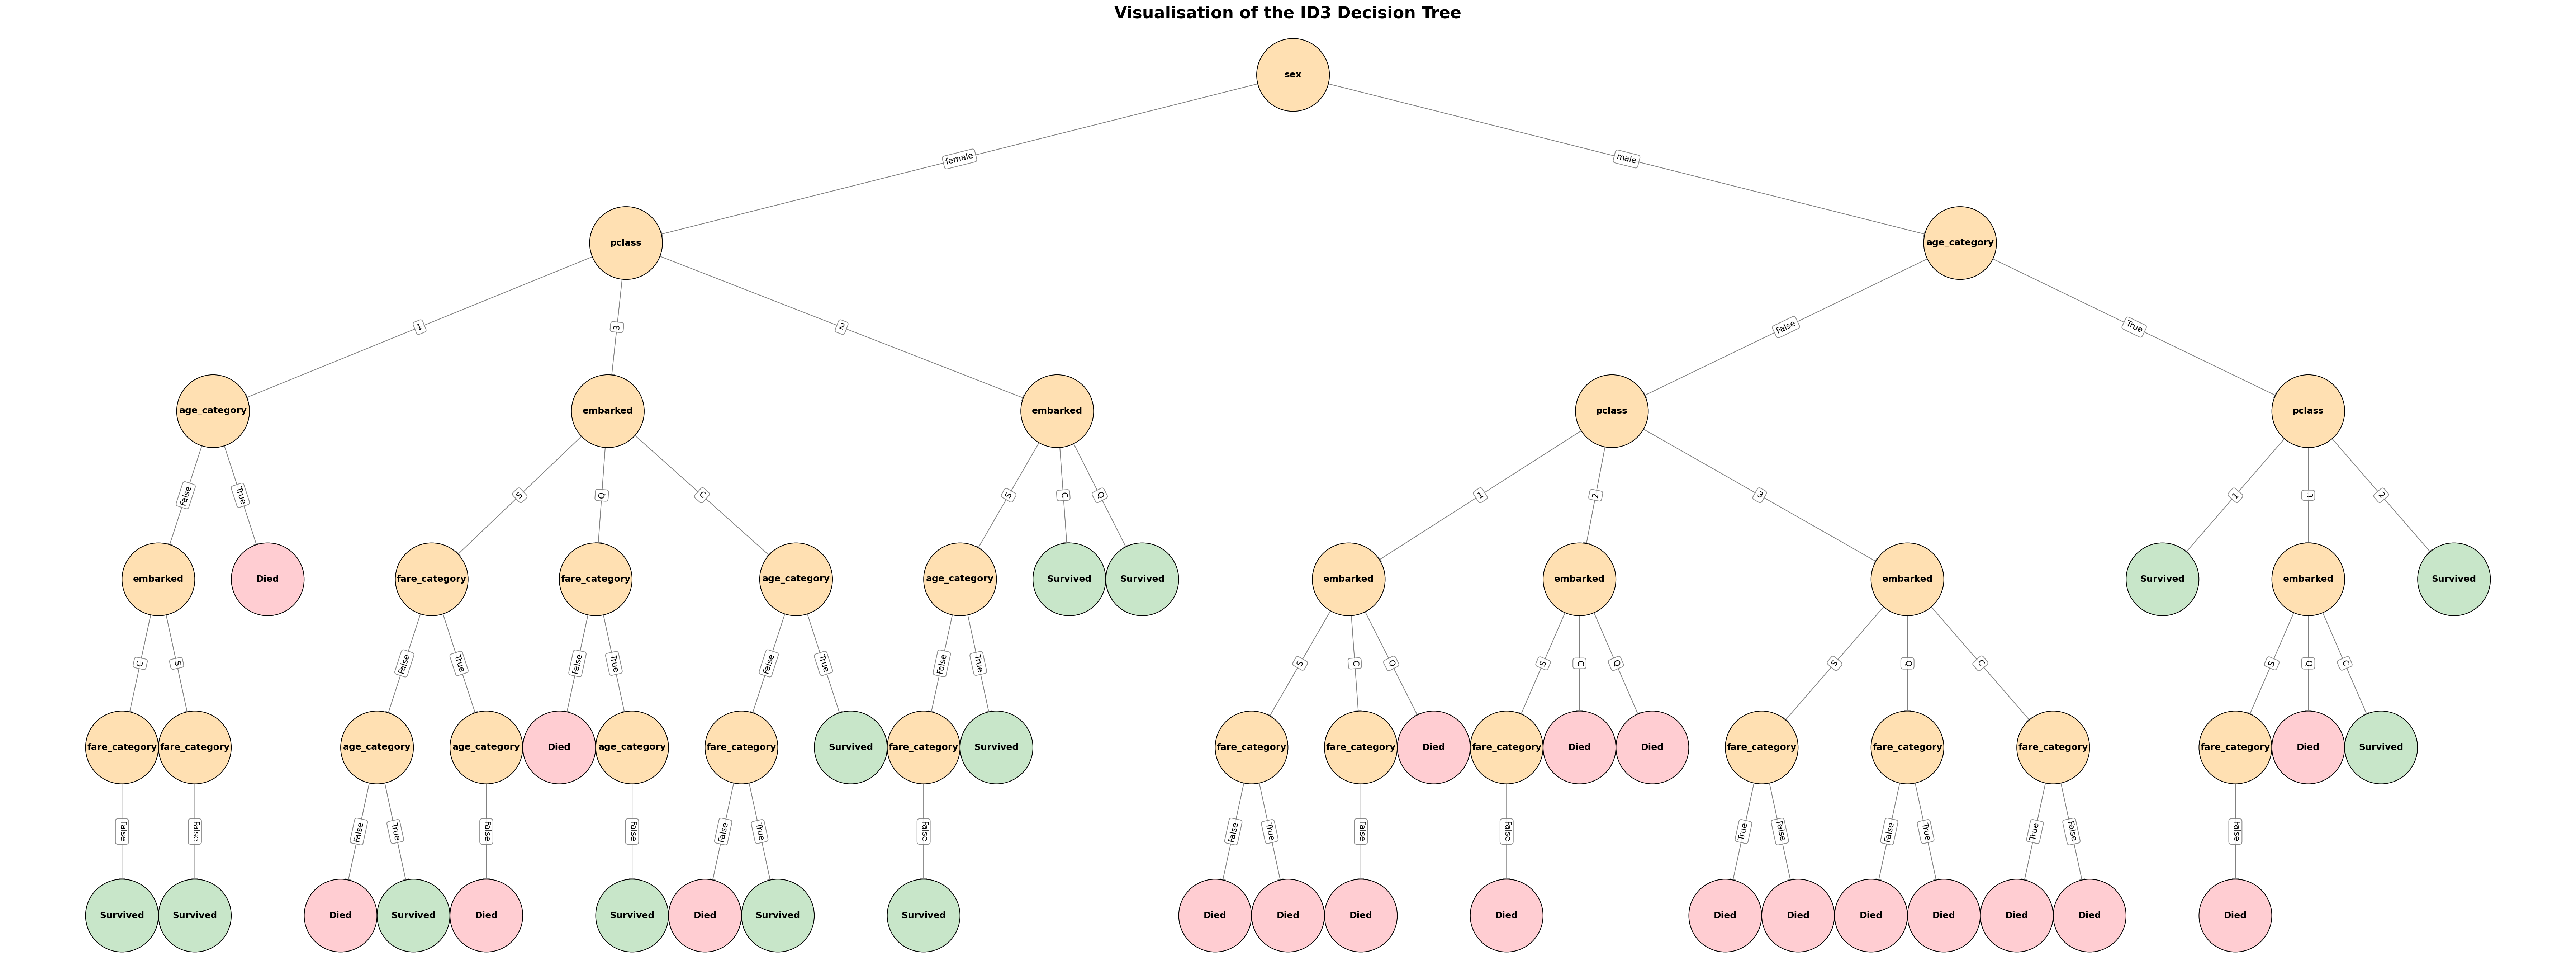

In [35]:
# DO NOT MODIFY
# Helper function to plot the nested dictionary as a directed graph

import networkx as nx
import uuid
import matplotlib.pyplot as plt

def visualise_tree_nx(tree):
    """
    Parses a nested dictionary decision tree and plots it using NetworkX.
    Uses a bottom-up layout, capped figure size, and high DPI for readability.
    """
    G = nx.DiGraph()
    pos = {}
    labels = {}
    edge_labels = {}
    node_colors = []

    # Global counter to assign a unique horizontal position to every leaf
    leaf_x_counter = [0]

    def build_graph(sub_tree, parent_id=None, edge_label=None, depth=0):
        node_id = str(uuid.uuid4())
        G.add_node(node_id)

        if parent_id is not None:
            G.add_edge(parent_id, node_id)
            edge_labels[(parent_id, node_id)] = edge_label

        # Base Case: Leaf Node
        if not isinstance(sub_tree, dict):
            prediction = "Survived" if str(sub_tree) == "1" else "Died"
            labels[node_id] = prediction

            # Green for survived, Red for died
            color = "#c8e6c9" if prediction == "Survived" else "#ffcdd2"
            node_colors.append(color)

            # Assign a unique horizontal position
            pos[node_id] = (leaf_x_counter[0], -depth)
            leaf_x_counter[0] += 1

            return node_id, pos[node_id][0]

        # Recursive Step: Decision Node
        feature = list(sub_tree.keys())[0]
        labels[node_id] = feature
        node_colors.append("#ffe0b2") # Orange for decision nodes

        branches = sub_tree[feature]
        child_x_coords = []

        # Build children and collect their X-coordinates
        for branch_val, next_subtree in branches.items():
            _, child_x = build_graph(next_subtree, node_id, str(branch_val), depth + 1)
            child_x_coords.append(child_x)

        # Parent's X coordinate is exactly in the middle of its children
        my_x = sum(child_x_coords) / len(child_x_coords) if child_x_coords else leaf_x_counter[0]
        pos[node_id] = (my_x, -depth)

        return node_id, my_x

    # Construct the graph and calculate positions
    build_graph(tree)

    plt.figure(figsize=(48, 18), dpi=150, facecolor='white')

    # Draw the components with significantly larger nodes
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=9500, edgecolors="black")
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True, arrowsize=20, node_size=6500)

    # Larger, bolder text for readability inside the cell
    nx.draw_networkx_labels(G, pos, labels, font_size=12, font_weight="bold")

    # Larger text for edge labels
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=11,
                                 bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9))

    # Add a generous margin so outermost nodes are not cut off
    ax = plt.gca()
    ax.margins(0.0)

    plt.title("Visualisation of the ID3 Decision Tree", fontsize=22, fontweight='bold', pad=20)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Execute the visualisation on the student's generated tree
visualise_tree_nx(decision_tree)

---

## 5. Inference and Model Evaluation

### 5.1 Question 10: Classifying with the Tree

*Requires: Cell 4.2*

Given a new data point, we must read down the tree and answer questions top-down. Implement a recursive function `predict_passenger(tree, passenger_data)` to navigate your nested dictionary and return a prediction (0 or 1).

In [37]:
# STUDENT ANSWER
def predict_passenger(tree, passenger_data):
    """
    Recursively traverses a decision tree to predict the target class for a single data point.

    Args:
        tree (dict or int/str): A nested dictionary representing the trained ID3 decision tree, or a discrete label if a leaf node has been reached.
        passenger_data (pd.Series or dict): A single instance of test data containing the categorical features for one passenger.

    Returns:
        int/str: The predicted class label for the given passenger (e.g., 0 or 1).
    """
    
    # TODO
    # Base case: leaf node
    if not isinstance(tree, dict):
        return tree

    # Current feature at this node
    feature = list(tree.keys())[0]
    branches = tree[feature]
    feature_value = passenger_data[feature]

    # Follow matching branch if it exists
    if feature_value in branches:
        return predict_passenger(branches[feature_value], passenger_data)

    # Fallback for unseen branch values
    return 0

# DO NOT MODIFY BELOW
predictions = []
for idx, row in test_df_discrete.iterrows():
    predictions.append(predict_passenger(decision_tree, row))

accuracy = np.mean(predictions == test_df_discrete['survived'])

EXPECTED_TEST_ACCURACY = 0.7902

assert np.isclose(accuracy, EXPECTED_TEST_ACCURACY, atol=1e-3), "Q10 Public Test Case Failed: Incorrect predictions generated"
print(f"Test Set Accuracy: {accuracy * 100:.2f}%")
print("Q10 Public Test Case Passed")

Test Set Accuracy: 79.02%
Q10 Public Test Case Passed


### 5.2 Question 11: Avoiding Overfitting

*Requires: Cell 5.1*

If a tree is allowed to grow indefinitely until every single passenger in the training set is perfectly classified, what problem is quite likely to occur, and how do we correct it?

* a) Overfitting; correct with pruning by replacing a subtree with a leaf node of the most common label if it lowers validation error.
* b) Underfitting; correct by forcing the ID3 algorithm to use Sum of Squares Error instead of Entropy.
* c) Information Loss; correct by discarding all continuous feature variables prior to processing.

Assign your chosen letter as a string to the variable `q11_ans`.

In [38]:
# STUDENT ANSWER
q11_ans = "a"

# DO NOT MODIFY BELOW
assert q11_ans in ["a", "b", "c"], "Q11 Public Test Case Failed: Invalid value"
print("Q11 Public Test Case Passed")

Q11 Public Test Case Passed


### Optional (Not for Marks): Submit to Kaggle

The dataset used in this lab is based off the Kaggle [Titanic - Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/overview) Competition. 

Now that you have built a fully functional Decision Tree from scratch, you can test it against the rest of the world! Your challenge is to adapt your implementation, process the official Kaggle test set, and submit your predictions to the public leaderboard. 

Kaggle has comprehensive documentation and getting-started guides to help you figure out exactly how to format and upload your submission. 

**Note:** On the leaderboard for this competition, you will see many people getting perfect scores of 100% accuracy. The reason for this is because the full dataset (including the test dataset used by Kaggle for scoring) is publicly available, and many people use these public answers to 'cheat' on these sorts of competitions. As usual, if you see an ML algorithm with reported 100% accuracy, there is definitely something dodgy going on.

# END